# Лабораторна робота №5
## Вступ до TensorFlow і побудова простої нейронної мережі для регресії

**Студент:** Михайло Вахнюк  
**Група:** МІТ-31  
**Варіант:** 5  

**Мета:** навчитися працювати з тензорами TensorFlow, побудувати та навчити нейронну мережу для регресії, оцінити її на незалежних даних, проаналізувати історію навчання й зберегти модель у форматі `.keras`.

**Індивідуальне завдання:** порівняти базову модель із моделлю, де в прихованих шарах використано функцію активації `tanh`.

TensorFlow — бібліотека для створення й навчання нейронної мережі. NumPy потрібний для числових даних, Matplotlib — для графіка навчання.

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
NumPy: 2.5.3


Підключаємо всі бібліотеки, потрібні для роботи. Вивід версій підтверджує, що TensorFlow успішно встановився, і його версію треба зазначити у звіті.
## Перевірка середовища

Підключено бібліотеки NumPy, TensorFlow і Matplotlib. Версії бібліотек виведено для фіксації середовища виконання та відтворюваності результатів.

In [2]:
a = tf.constant([[1., 2.], [3., 4.]], dtype=tf.float32)
b = tf.constant([10., 20.])

w = tf.Variable([0.2, 0.5])
w.assign([0.3, 0.6])

print("shape a:", a.shape)
print("dtype a:", a.dtype)
print("rank a:", tf.rank(a).numpy())

print("\na + b:")
print(a + b)

print("\na * a:")
print(a * a)

print("\ntf.matmul(a, a):")
print(tf.matmul(a, a))

print("\nw після assign:")
print(w.numpy())

shape a: (2, 2)
dtype a: <dtype: 'float32'>
rank a: 2

a + b:
tf.Tensor(
[[11. 22.]
 [13. 24.]], shape=(2, 2), dtype=float32)

a * a:
tf.Tensor(
[[ 1.  4.]
 [ 9. 16.]], shape=(2, 2), dtype=float32)

tf.matmul(a, a):
tf.Tensor(
[[ 7. 10.]
 [15. 22.]], shape=(2, 2), dtype=float32)

w після assign:
[0.3 0.6]


Коментар: tf.constant створює незмінний тензор, а tf.Variable — змінний, значення якого можна оновлювати під час навчання моделі. shape показує розміри тензора, dtype — тип даних, а rank — кількість осей. Додавання a + b працює через broadcasting: вектор b застосовується до кожного рядка матриці a. Вираз a * a множить елементи на відповідні елементи, а tf.matmul(a, a) виконує матричне множення.

## Робота з тензорами

Створено незмінні тензори `tf.constant` і змінну `tf.Variable`. Тензор `a` має ранг 2, форму `(2, 2)` та тип `float32`. Операція `a + b` можлива завдяки broadcasting: вектор `b` додається до кожного рядка матриці `a`. Поелементне множення `a * a` відрізняється від `tf.matmul(a, a)`, оскільки другий вираз виконує матричне множення.

In [3]:
SEED = 42

keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

x = np.linspace(-5, 5, 600, dtype=np.float32)
noise = rng.normal(0, 0.7, x.shape).astype(np.float32)

y = 3 * x + 2 + 0.8 * np.sin(2 * x) + noise

x = x.reshape(-1, 1)
y = y.reshape(-1, 1)

idx = rng.permutation(len(x))
x, y = x[idx], y[idx]

x_train, y_train = x[:420], y[:420]
x_val, y_val = x[420:510], y[420:510]
x_test, y_test = x[510:], y[510:]

print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)
print("Тип даних x:", x.dtype)

Train: (420, 1) (420, 1)
Validation: (90, 1) (90, 1)
Test: (90, 1) (90, 1)
Тип даних x: float32


Коментар: створюємо 600 штучних прикладів, де між x та y є нелінійний зв’язок через sin(2*x) і випадковий шум. Потім перемішуємо дані та ділимо їх: 420 прикладів (70%) для навчання, 90 (15%) для validation і 90 (15%) для фінального test. validation використовується для вибору кращої моделі, а test не можна використовувати для підбору гіперпараметрів.

## Підготовка даних

Згенеровано 600 відтворюваних прикладів нелінійної регресії з випадковим шумом. Дані перемішано та поділено у співвідношенні 70% / 15% / 15% на навчальну, валідаційну й тестову вибірки. Кожен об’єкт має один вхід, тому форма матриці ознак має вигляд `(кількість об’єктів, 1)`. Для порівняння моделей використовується однаковий поділ даних.

In [4]:
def build_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1)
    ])

model = build_model()

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

model.summary()

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)

print("Найменший val_loss:", min(history.history["val_loss"]))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

Найменший val_loss: 0.5986483693122864


Коментар: базова модель має один вхід, два приховані шари по 16 нейронів із функцією активації relu та вихідний шар Dense(1) без активації, бо прогнозуємо числове значення. compile() задає алгоритм Adam, функцію втрат MSE і метрику MAE. fit() навчає модель на train та після кожної епохи перевіряє її на validation. Найменший val_loss потрібен для порівняння baseline з моделлю варіанта 5.

## Базова нейронна мережа

Побудовано базову модель `Sequential` з двома прихованими шарами `Dense(16, relu)` і вихідним шаром `Dense(1)`. Модель навчається оптимізатором Adam з learning rate 0.01, функцією втрат MSE та метрикою MAE. Валідаційна вибірка використовується для контролю навчання й вибору кращого варіанта моделі.

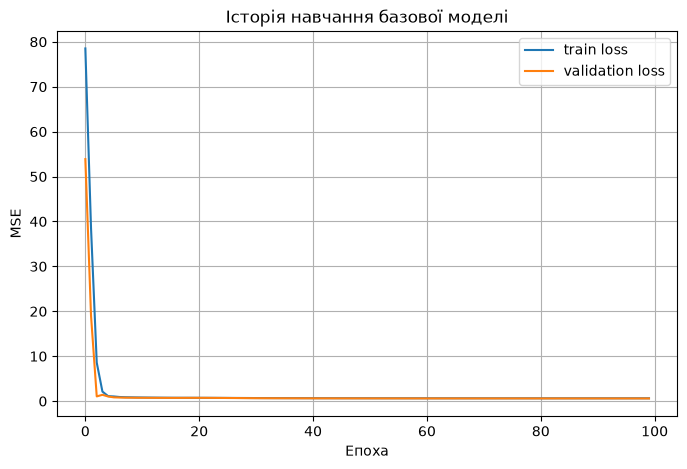

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")

plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.title("Історія навчання базової моделі")
plt.legend()
plt.grid(True)

plt.show()

Коментар: loss показує помилку моделі на навчальній вибірці, а val_loss — на незалежній валідаційній. За цими кривими оцінюємо, як модель навчається. Якщо train loss зменшується, а val_loss починає зростати, це може свідчити про перенавчання.

### Аналіз навчання базової моделі

Побудовано графік `loss` і `val_loss` за 100 епох. Криві показують зміну MSE на навчальній та валідаційній вибірках. Найменше значення `val_loss` використовується для порівняння базової моделі з моделлю індивідуального варіанта.

In [6]:
keras.utils.set_random_seed(SEED)

def build_tanh_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation="tanh"),
        layers.Dense(16, activation="tanh"),
        layers.Dense(1)
    ])

model_tanh = build_tanh_model()

model_tanh.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

history_tanh = model_tanh.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)

print("Найменший val_loss baseline:", min(history.history["val_loss"]))
print("Найменший val_loss tanh:", min(history_tanh.history["val_loss"]))

Найменший val_loss baseline: 0.5986483693122864
Найменший val_loss tanh: 0.4313772916793823


Коментар: у варіанті 5 змінюємо лише функцію активації прихованих шарів. tanh перетворює значення в діапазон від -1 до 1, тоді як relu залишає додатні значення без змін, а від’ємні перетворює на нуль. keras.utils.set_random_seed(SEED) перед створенням моделі робить порівняння чеснішим: для обох моделей фіксується випадковість ініціалізації ваг.

## Індивідуальний варіант 5

Створено другу модель з такою самою архітектурою, але з функцією активації `tanh` у двох прихованих шарах. Інші налаштування — кількість нейронів, оптимізатор, learning rate, кількість епох і batch size — залишено без змін. Моделі порівнюються передусім за найменшим `val_loss`, оскільки валідаційна вибірка призначена для вибору варіанта моделі.

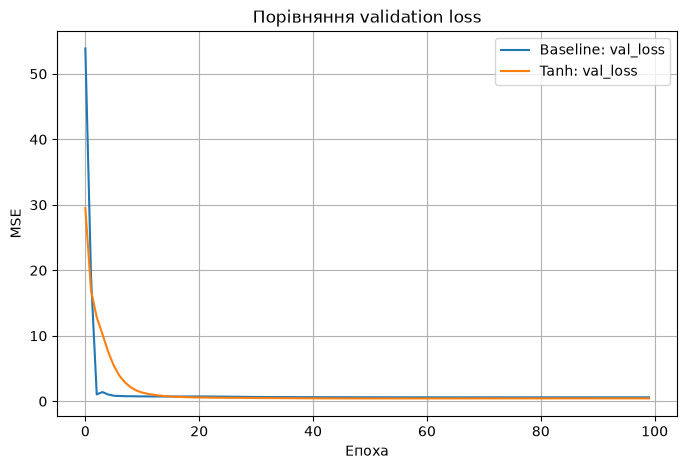

Найменший val_loss baseline: 0.5986483693122864
Найменший val_loss tanh: 0.4313772916793823


In [7]:
baseline_min_val_loss = min(history.history["val_loss"])
tanh_min_val_loss = min(history_tanh.history["val_loss"])

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["val_loss"],
    label="Baseline: val_loss"
)

plt.plot(
    history_tanh.history["val_loss"],
    label="Tanh: val_loss"
)

plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.title("Порівняння validation loss")
plt.legend()
plt.grid(True)

plt.show()

print("Найменший val_loss baseline:", baseline_min_val_loss)
print("Найменший val_loss tanh:", tanh_min_val_loss)

Коментар: порівнюємо моделі саме за val_loss, бо validation-набір не брав участі у навчанні. Кращим кандидатом є модель з меншим найменшим val_loss. Test-вибірку поки не використовуємо, щоб не підбирати модель під тестові дані.

### Порівняння моделей за validation

Для baseline-моделі та моделі з `tanh` побудовано графік валідаційної MSE. Кращою за validation вважається модель із меншим мінімальним значенням `val_loss`. Test-вибірка на цьому етапі не використовується, оскільки вона призначена лише для фінальної незалежної оцінки.

In [8]:
if tanh_min_val_loss < baseline_min_val_loss:
    best_model = model_tanh
    best_model_name = "Tanh model"
else:
    best_model = model
    best_model_name = "Baseline model"

baseline_test = model.evaluate(
    x_test,
    y_test,
    return_dict=True,
    verbose=0
)

tanh_test = model_tanh.evaluate(
    x_test,
    y_test,
    return_dict=True,
    verbose=0
)

comparison = pd.DataFrame(
    [
        {
            "Модель": "Baseline (relu)",
            "Мінімальний val_loss": baseline_min_val_loss,
            "Test MSE": baseline_test["loss"],
            "Test MAE": baseline_test["mae"]
        },
        {
            "Модель": "Варіант 5 (tanh)",
            "Мінімальний val_loss": tanh_min_val_loss,
            "Test MSE": tanh_test["loss"],
            "Test MAE": tanh_test["mae"]
        }
    ]
)

display(comparison.round(4))
print("Краща модель за validation:", best_model_name)

,Модель,Мінімальний val_loss,Test MSE,Test MAE
0,Baseline (relu),0.5986,0.6071,0.6143
1,Варіант 5 (tanh),0.4314,0.4698,0.5312


Краща модель за validation: Tanh model


Коментар: модель обирається за найменшим val_loss, а не за test-метриками. Після вибору test застосовується для фінальної незалежної оцінки. У таблиці є всі обов’язкові результати: мінімальний val_loss, test MSE і test MAE для baseline та варіанта 5.

## Порівняння baseline і варіанта 5

Моделі порівняно за мінімальним значенням `val_loss`, test MSE та test MAE. Вибір кращої моделі зроблено за validation, а test-вибірку використано для фінальної оцінки. Такий порядок запобігає підбору моделі під тестові дані.

In [9]:
x_new = np.array([[-4.], [0.], [4.]], dtype=np.float32)

y_new_pred = best_model.predict(x_new, verbose=0)

predictions_table = pd.DataFrame({
    "x": x_new.flatten(),
    "Прогноз y": y_new_pred.flatten()
})

display(predictions_table.round(3))

,x,Прогноз y
0,-4.0,-10.696
1,0.0,2.104
2,4.0,14.772


Коментар: створюємо три нові значення входу x = -4, 0 і 4. Краща за validation модель обчислює для них числові прогнози y. Це демонструє застосування predict() до нових даних, яких не було у навчальній вибірці.

## Прогнозування нових значень

Для трьох нових значень `x = -4`, `0` і `4` отримано прогнози кращої моделі. Метод `predict()` повертає числові значення цільової змінної, оскільки задача є регресією.

In [10]:
model_path = "lab5_model.keras"

best_model.save(model_path)

restored = keras.models.load_model(model_path)

np.testing.assert_allclose(
    best_model.predict(x_new, verbose=0),
    restored.predict(x_new, verbose=0),
    rtol=1e-5
)

print(f"Модель збережено у файлі: {model_path}")
print("Перевірку пройдено: прогнози до і після завантаження збігаються.")

Модель збережено у файлі: lab5_model.keras
Перевірку пройдено: прогнози до і після завантаження збігаються.


Коментар: .keras зберігає архітектуру моделі, її ваги та налаштування. Потім модель завантажується у змінну restored. assert_allclose перевіряє, що її прогнози практично збігаються з прогнозами збереженої моделі; невелика похибка дозволена через обчислення з плаваючою комою.

## Збереження та перевірка моделі

Кращу за validation модель збережено у форматі `.keras`, після чого її завантажено повторно. Збіг прогнозів оригінальної та завантаженої моделей перевірено з допустимою похибкою обчислень. Це підтверджує, що модель можна коректно зберігати та використовувати повторно.

## Висновок

У роботі було опрацьовано основи TensorFlow: створення тензорів, визначення їхньої форми, рангу та типу даних, а також broadcasting і матричні операції. Для штучно згенерованих даних нелінійної регресії побудовано базову нейронну мережу та модель індивідуального варіанта з функцією активації `tanh`. Моделі порівняно за мінімальним `val_loss`, test MSE і test MAE, причому вибір кращої моделі виконано за validation-вибіркою. Для кращої моделі отримано прогнози нових значень, її збережено у форматі `.keras` і успішно завантажено повторно. Test-вибірка використовувалась лише для остаточної незалежної оцінки, що запобігає витоку даних і некоректному добору моделі.